# 01 · GRPO Core: Group-Relative Advantages and the Clipped Update

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/samaksh97/grpo-then-and-now/blob/main/notebook/01_grpo_core.ipynb)

**GRPO, Then and Now** · core notebook · **about 30 minutes** · CPU only, runs in about 3 seconds

> **GRPO learns only from reward differences within a group of sampled responses.**

You will compute GRPO's group-relative advantages by hand on a KernelBench-framed toy, write a complete Bandit-GRPO update in about 20 lines, and run the full clipped objective with a KL penalty on a 4-token sequence policy.

**You need:** basic RL (policies, rewards, policy gradients, PPO). New to these? Run `00_pg_ppo_refresher.ipynb` or read the GRPO deck `../slides/grpo_intro.html` up to its [score-the-rollouts slide](../slides/grpo_intro.html#score-rollouts) first. **Then:** `02_failure_lab.ipynb` (where the learning signal breaks) and `03_exercises.ipynb`.

By the end you can (1) compute group-relative advantages and explain why they sum to zero, (2) implement a verifier-based GRPO update, and (3) say when a clipped token stops contributing gradient.

**Notation used throughout**

| Symbol | Meaning |
|---|---|
| $\pi_\theta$, $\pi_{\text{old}}$, $\pi_{\text{ref}}$ | current policy; frozen policy that sampled the rollouts; frozen reference policy for the KL term |
| $G$, $o_i$, $\lvert o_i\rvert$ | group size; $i$-th sampled response; its length in tokens |
| $R_i$, $A_i$ | reward of response $i$; its group-relative advantage $(R_i-\bar R)/\sigma(R)$ |
| $r_{i,t}(\theta)$ | importance ratio $\pi_\theta/\pi_{\text{old}}$ of token $t$ of response $i$ |
| $\epsilon$ ($\epsilon_{\text{low}}$, $\epsilon_{\text{high}}$) | clip range of the ratio (DAPO decouples the lower and upper bounds) |

> **Scope.** Real KernelBench task specifications are paired with illustrative benchmark outcomes; no GPU or `nvcc` is used (see `../data/kernelbench/README.md`).

In [1]:
# Setup: make grpo_lab importable
import sys, pathlib, subprocess
ROOT = next((p for p in (pathlib.Path.cwd(), pathlib.Path.cwd().parent) if (p / "grpo_lab").exists()), None)
if ROOT is None:   # e.g. opened in Colab: fetch the repository (code, data and figures) first
    subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/samaksh97/grpo-then-and-now"], check=True)
    ROOT = pathlib.Path("grpo-then-and-now").resolve()
sys.path.insert(0, str(ROOT))
import numpy as np
from grpo_lab import data, envs, objectives, plots
from grpo_lab.objectives import softmax, entropy

cfg = envs.Config()
CANDIDATES = data.matmul_task()["candidates"]
envs.describe_bandit(CANDIDATES, cfg.bandit_correct_action)
envs.describe_sequence()

Level A: 8 candidate kernels for KernelBench L1-P1 (square matmul)
  [0] Tile 16x16 (Naive global loads)               178.1 us  0.80x  reward=0.0
  [1] Tile 16x32 (Uncoalesced strided memory)       156.6 us  0.91x  reward=0.0
  [2] Tile 64x64 (Register pressure spill)          192.5 us  0.74x  reward=0.0
  [3] Tile 32x32 + SharedMem + Coalesced             60.8 us  2.34x  reward=1.0  <-- target
  [4] Tile 8x8 (Low occupancy under-utilization)    268.8 us  0.53x  reward=0.0
  [5] Tile 32x16 (Shared memory bank conflicts)     151.6 us  0.94x  reward=0.0
  [6] Tile 128x128 (Shared mem capacity overflow)     0.0 us  0.00x  reward=0.0
  [7] Tile 16x16 + Non-atomic accum (race)           55.0 us  2.59x  reward=0.0
Level B: 4-stage pipeline over 6 stages ['load_coalesced', 'sync_store', 'alloc_shared', 'busy_wait', 'tile_compute', 'assert_check']
  target: alloc_shared -> load_coalesced -> tile_compute -> sync_store


## 1 · One GRPO step, and two toy environments *(about 3 min)*

![Flow diagram of one GRPO step: a prompt goes to the frozen policy, which samples a group of 8 rollouts (2 pass, 6 fail); a verifier scores them 1 or 0; the group-relative advantages are +1.73 for passes and -0.58 for fails; a clipped policy update makes passing rollouts more likely, and the updated policy samples the next batch.](attachment:F01_anatomy_of_one_grpo_step.png)

**What you'll observe:** every box in F1 becomes a few lines of NumPy below. We use two transparent toys:

| Micro-Environment | KernelBench Framing | Formulation | Failure Modes Demonstrated |
|---|---|---|---|
| **Level A: Micro-Bandit** | **Kernel configuration selection** for the Square-Matmul problem: pick the tile/block geometry (16x16, 32x32, 64x64, shared-memory layouts) | 8-action categorical policy with a deterministic reward from the task's candidate outcomes | Zero-gradient groups, group-size scaling ($G$), advantage normalization |
| **Level B: Micro-Sequence** | **Multi-stage kernel construction:** emit the 4 core stages of a tiled kernel (`alloc_shared → load_coalesced → tile_compute → sync_store`) | 4-step autoregressive categorical policy with a sequence verifier | Entropy collapse, clipping asymmetry, length bias |
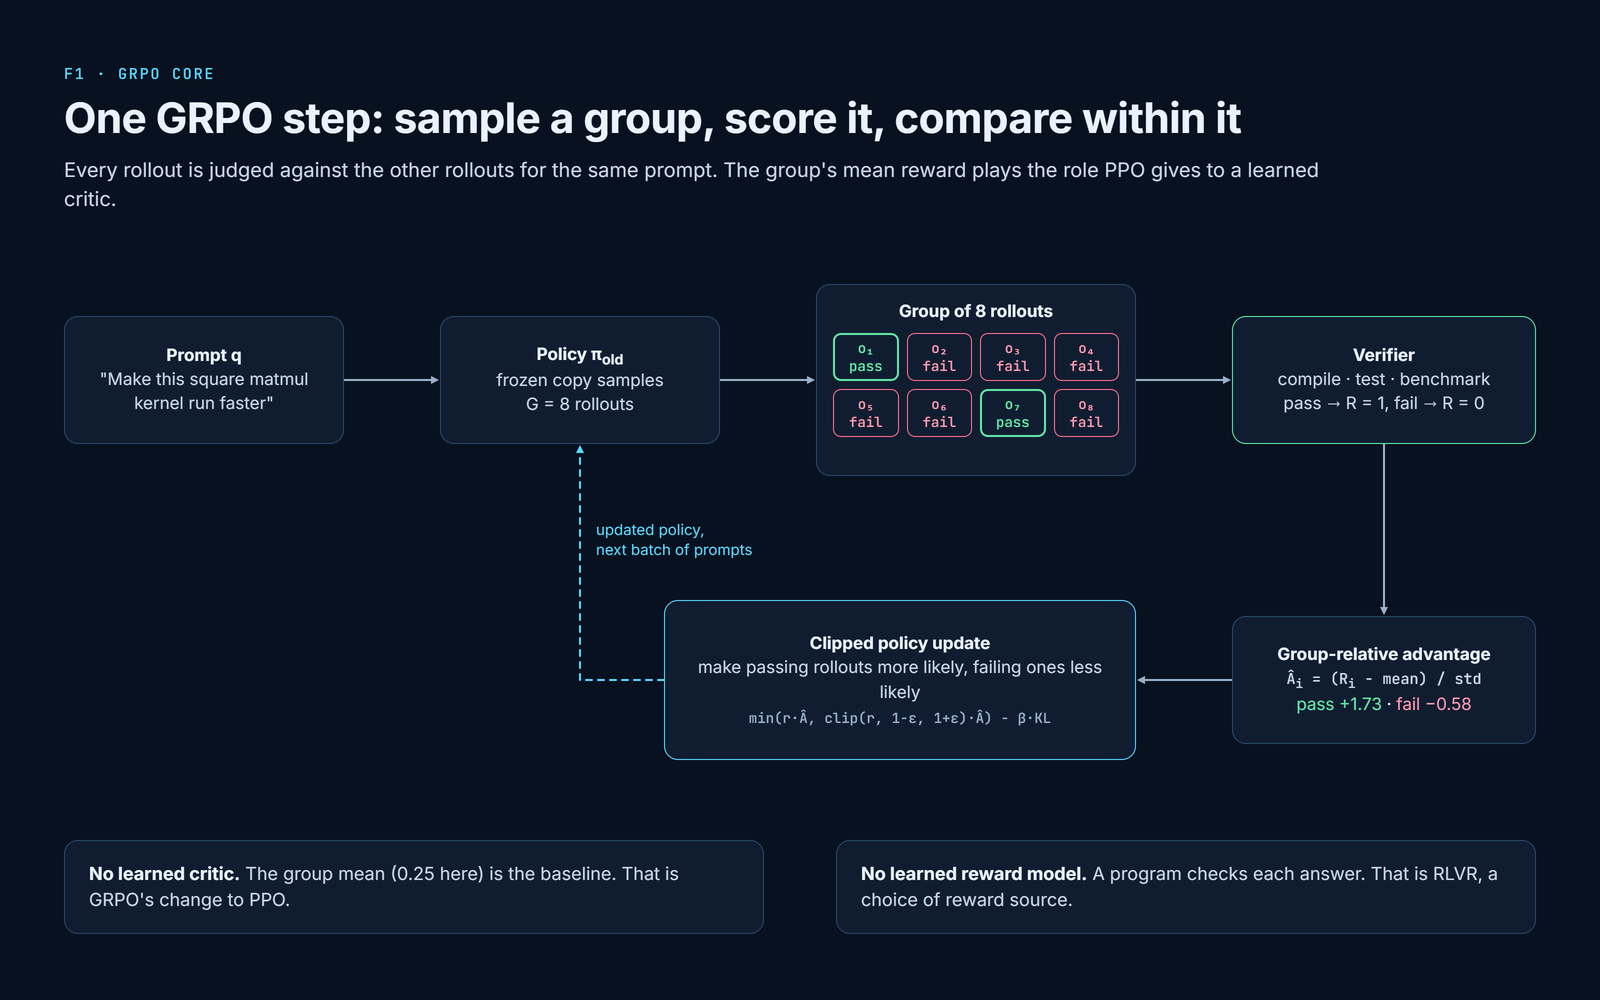

## 2 · GRPO by hand on the bandit *(about 10 min)*

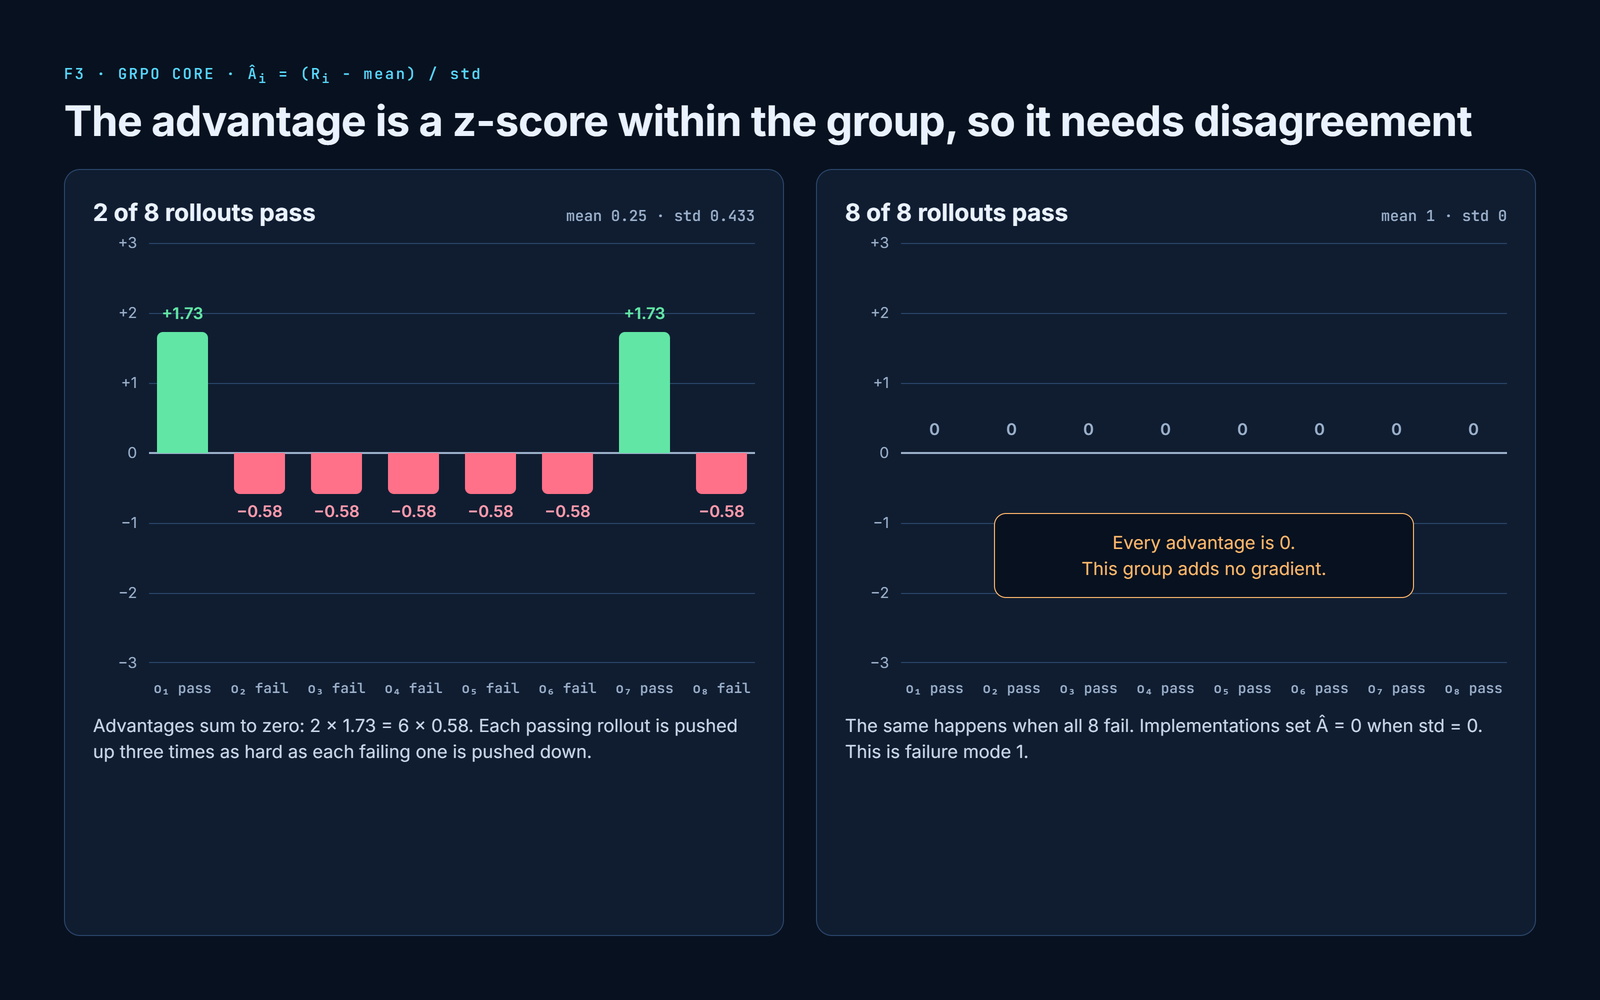

**What you'll observe:** in a group where two of eight rollouts pass, each passing rollout gets about +1.7 and each failing one about −0.6, and the advantages sum to zero.

Let's trace GRPO's core mathematical update step by step. For a prompt $s$, GRPO executes:

1. **Sample Group:** Generate $G$ candidate rollouts $\{a_1, \dots, a_G\} \sim \pi_\theta(\cdot \mid s)$.
2. **Score with Verifier:** Evaluate each candidate with the execution verifier to obtain rewards $\{R_1, \dots, R_G\}$.
3. **Compute Group-Relative Advantage:**
   $$A_i = \frac{R_i - \text{mean}(R_1, \dots, R_G)}{\text{std}(R_1, \dots, R_G) + \epsilon}$$
4. **Policy Update:** Increase the generation probability of above-average candidates ($A_i > 0$) and decrease below-average ones ($A_i < 0$).

Notice again: **the group itself is the baseline**, so GRPO needs no learned critic/value network. The reward source is separate: this RLVR example uses a programmatic verifier, while GRPO can also consume other scalar reward sources.

Let's compute this by hand in Python for our Kernel Selection task.

mean(R) = 0.250, std(R) = 0.433
  Tile 64x64 (Register pressure spill)         R = 0  A = -0.577
  Tile 32x32 + SharedMem + Coalesced           R = 1  A = +1.732
  Tile 32x16 (Shared memory bank conflicts)    R = 0  A = -0.577
  Tile 16x16 (Naive global loads)              R = 0  A = -0.577
  Tile 8x8 (Low occupancy under-utilization)   R = 0  A = -0.577
  Tile 16x32 (Uncoalesced strided memory)      R = 0  A = -0.577
  Tile 32x32 + SharedMem + Coalesced           R = 1  A = +1.732
  Tile 16x16 + Non-atomic accum (race)         R = 0  A = -0.577
sum of advantages = 0.000000


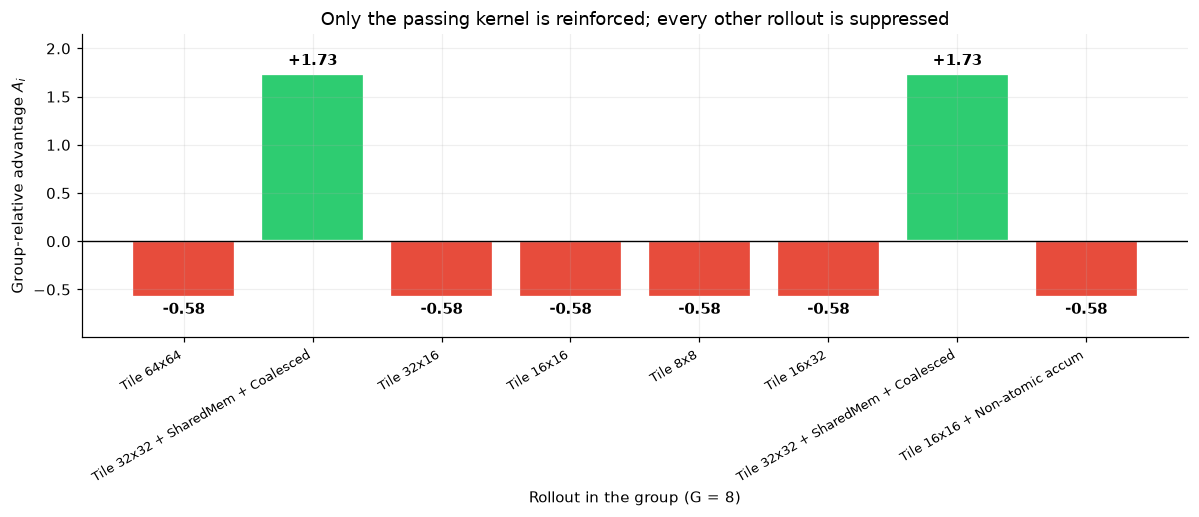

In [2]:
verifier = envs.BanditVerifier(CANDIDATES, correct_action=cfg.bandit_correct_action)
# One group of G = 8 rollouts for the prompt; it contains the passing kernel (index 3) twice
group_actions = np.array([2, 3, 5, 0, 4, 1, 3, 7])
group_rewards = np.array([verifier(a) for a in group_actions])
# Group-relative advantage: subtract the group mean, divide by the group std (population, ddof=0)
advantages = (group_rewards - group_rewards.mean()) / (group_rewards.std() + 1e-8)

print(f"mean(R) = {group_rewards.mean():.3f}, std(R) = {group_rewards.std():.3f}")
for a, r, adv in zip(group_actions, group_rewards, advantages):
    print(f"  {CANDIDATES[a]['name']:<44} R = {int(r)}  A = {adv:+.3f}")
print(f"sum of advantages = {advantages.sum():.6f}")
plots.advantage_bars(advantages, [CANDIDATES[a]["name"].split("(")[0].strip() for a in group_actions])

### 2.2 Bandit-GRPO in about 20 lines

The update samples a group, scores it, turns rewards into advantages, and takes one gradient step. For a softmax policy, $\nabla_{\text{logits}}\log\pi(a) = \text{onehot}(a) - \pi$, so the gradient is the advantage-weighted average of that vector over the group.

In [3]:
def bandit_grpo_step(logits, verifier, group_size, lr):
    """One Bandit-GRPO step on a softmax policy, logits shape (K,); same as grpo_lab.objectives."""
    probs = softmax(logits)
    actions = np.random.choice(len(logits), size=group_size, p=probs)    # 1) sample a group of G
    rewards = np.array([verifier(a) for a in actions])                    # 2) score it
    info = {"reward_mean": rewards.mean(), "entropy": entropy(probs), "p_correct": probs[verifier.correct]}
    if rewards.std() < 1e-8:                                              # identical rewards: no signal
        return logits, {**info, "grad_norm": 0.0, "zero_grad": True}
    advantages = (rewards - rewards.mean()) / rewards.std()               # 3) group-relative advantage
    grad = np.zeros_like(logits)
    for a, adv in zip(actions, advantages):                               # 4) A * (onehot(a) - probs)
        grad += adv * (np.eye(len(logits))[a] - probs)
    grad /= group_size
    logits = logits + lr * grad                                           # 5) gradient ascent
    new_probs = softmax(logits)
    return logits, {"reward_mean": rewards.mean(), "entropy": entropy(new_probs), "grad_norm": np.linalg.norm(grad),
                    "zero_grad": False, "p_correct": new_probs[verifier.correct]}

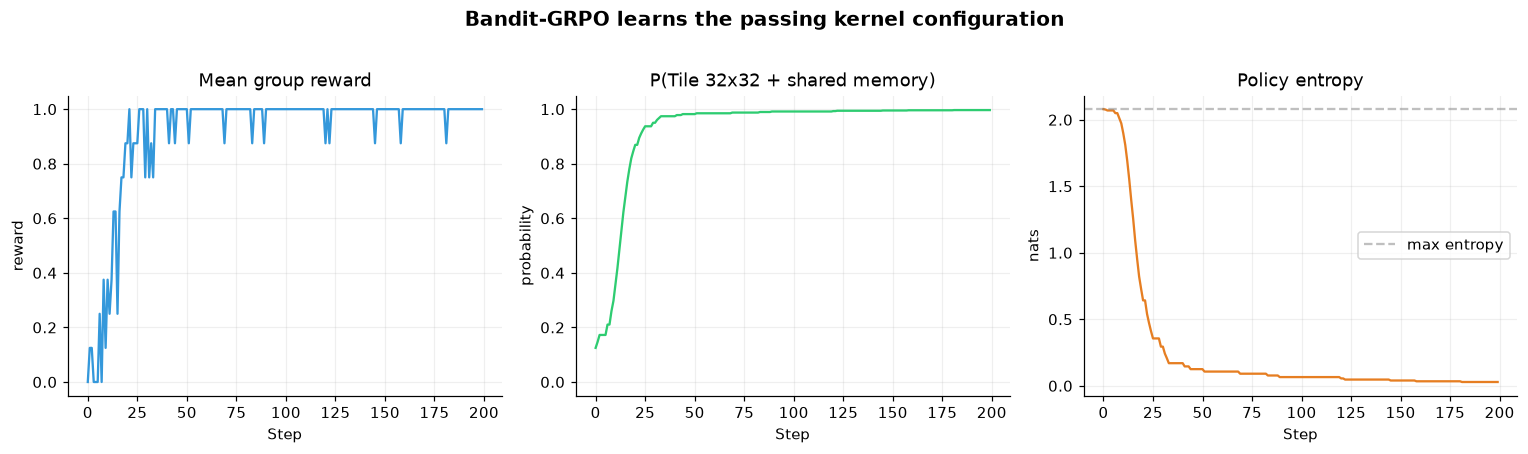

  P = 0.001  Tile 16x16 (Naive global loads)
  P = 0.000  Tile 16x32 (Uncoalesced strided memory)
  P = 0.001  Tile 64x64 (Register pressure spill)
  P = 0.997  Tile 32x32 + SharedMem + Coalesced  <-- target
  P = 0.000  Tile 8x8 (Low occupancy under-utilization)
  P = 0.000  Tile 32x16 (Shared memory bank conflicts)
  P = 0.001  Tile 128x128 (Shared mem capacity overflow)
  P = 0.000  Tile 16x16 + Non-atomic accum (race)


In [4]:
np.random.seed(cfg.seed)
logits, history = np.zeros(cfg.bandit_n_actions), []
for step in range(cfg.bandit_n_steps):
    logits, info = bandit_grpo_step(logits, verifier, cfg.bandit_group_size, cfg.bandit_lr)
    history.append(info)
plots.bandit_training(history, cfg.bandit_n_actions, target_name="Tile 32x32 + shared memory")

final = softmax(logits)
for i, c in enumerate(CANDIDATES):
    print(f"  P = {final[i]:.3f}  {c['name']}" + ("  <-- target" if i == cfg.bandit_correct_action else ""))

### Key Observation: Learning from Group Contrast

With about 20 lines of code and zero learned critic weights, GRPO rapidly learns to identify the optimal kernel configuration (`Tile 32x32 + SharedMem`). 

The learning signal is driven entirely by **group contrast**: the optimal configuration is reinforced whenever it appears alongside suboptimal configurations in the same group.

*Next, let's extend this to full autoregressive token sequences with clipping and KL regularization.*

## 3 · The full GRPO objective on token sequences *(about 10 min)*

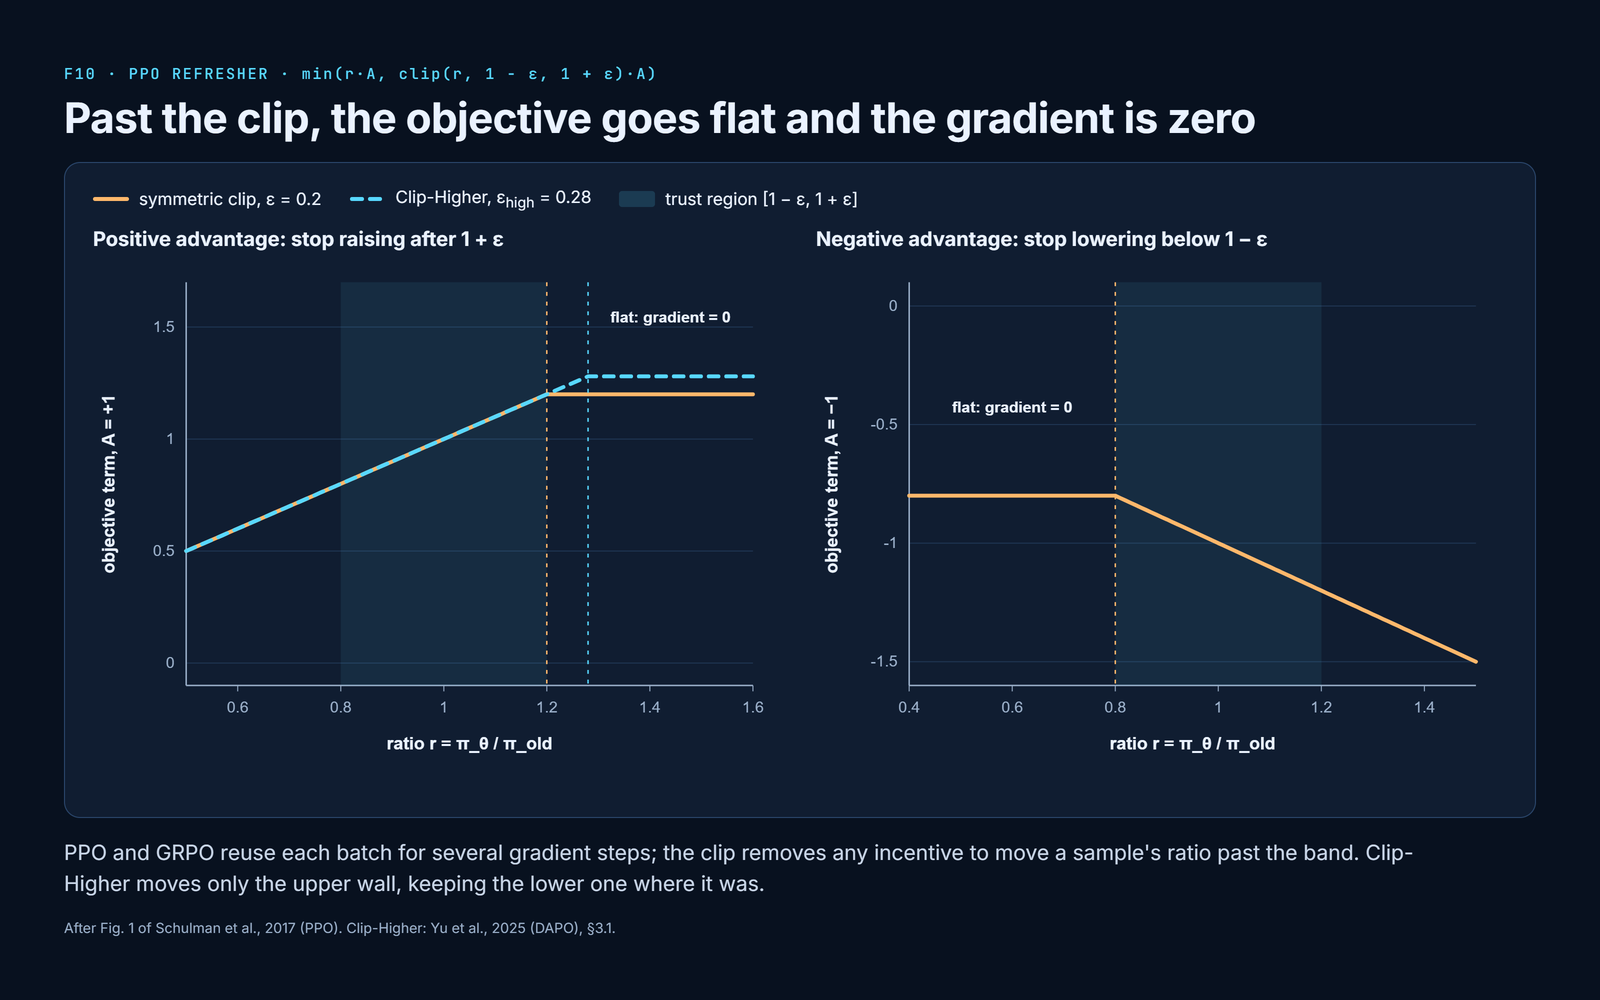

**What you'll observe:** over repeated optimizer epochs on one sampled group, token ratios drift away from 1 until the clip bound stops them.

> **TL;DR:** full GRPO is PPO's clipped objective (ratio, clip and KL) with group-relative advantages in place of a critic. The code below implements it on a 4-token toy.

While the bandit case is intuitive, production reasoning and code generation models operate on **multi-token autoregressive sequences**. Full GRPO incorporates three essential mechanisms from PPO:

1. **Importance Sampling Ratio:** When performing multiple gradient steps per rollout batch, the policy shifts from $\pi_{\text{old}}$ (which generated the rollout) to $\pi_\theta$ (being updated):

$$
r_{i,t}(\theta) = \frac{\pi_\theta(a_{i,t} \mid a_{i,<t}, s)}{\pi_{\text{old}}(a_{i,t} \mid a_{i,<t}, s)}
$$

2. **Clipped Surrogate Objective:** To prevent catastrophic policy shifts, the ratio is clipped to $[1-\epsilon, 1+\epsilon]$:

$$
\mathcal{L}_{\text{clip}}(\theta) = \min\left( r_{i,t}(\theta) A_i, \; \text{clip}(r_{i,t}(\theta), 1-\epsilon, 1+\epsilon) A_i \right)
$$

3. **KL Regularization Penalty:** A per-token penalty prevents the policy from drifting too far from the reference model $\pi_{\text{ref}}$:

$$
\mathbb{D}_{\text{KL}}(\pi_\theta \parallel \pi_{\text{ref}}) = \sum_a \pi_\theta(a)\left[\log \pi_\theta(a)-\log \pi_{\text{ref}}(a)\right]
$$

Combining these yields the full Sequence-GRPO objective:

$$
\mathcal{L}_{\text{GRPO}}(\theta) = -\frac{1}{G}\sum_{i=1}^G \frac{1}{|o_i|} \sum_{t=1}^{|o_i|} \left[ \min\left( r_{i,t}(\theta) A_i, \text{clip}(r_{i,t}(\theta), 1-\epsilon, 1+\epsilon) A_i \right) - \beta \mathbb{D}_{\text{KL}}(\pi_\theta \parallel \pi_{\text{ref}}) \right]
$$

In [5]:
from grpo_lab.objectives import clip_is_active, sequence_grpo_step

def token_gradient(advantage, ratio, probs, action, eps_low=0.2, eps_high=0.2, norm=1.0):
    """d/d logits of min(r A, clip(r) A) for one sampled token; zero once the clip binds (DAPO Eq. 8)."""
    if not clip_is_active(advantage, ratio, eps_low, eps_high):
        return np.zeros_like(probs)
    return norm * advantage * ratio * (np.eye(len(probs))[action] - probs)   # A r (onehot - probs)

probs = softmax(np.array([1.0, 0.0, 0.0]))
for r in (1.05, 1.25):
    print(f"ratio {r:.2f}, A = +1: gradient on the logits = {np.round(token_gradient(+1.0, r, probs, 0), 3)}")

ratio 1.05, A = +1: gradient on the logits = [ 0.445 -0.223 -0.223]
ratio 1.25, A = +1: gradient on the logits = [0. 0. 0.]


`token_gradient` is the heart of `grpo_lab.objectives.sequence_grpo_step` (about 60 lines, annotated with DeepSeekMath Eq. 3). That function also samples the group with a frozen $\pi_{\text{old}}$, loops over several optimizer epochs on the same rollouts, and adds the KL penalty. The next cell trains the 4-token toy with a shaped verifier (the fraction of positions that match the target).

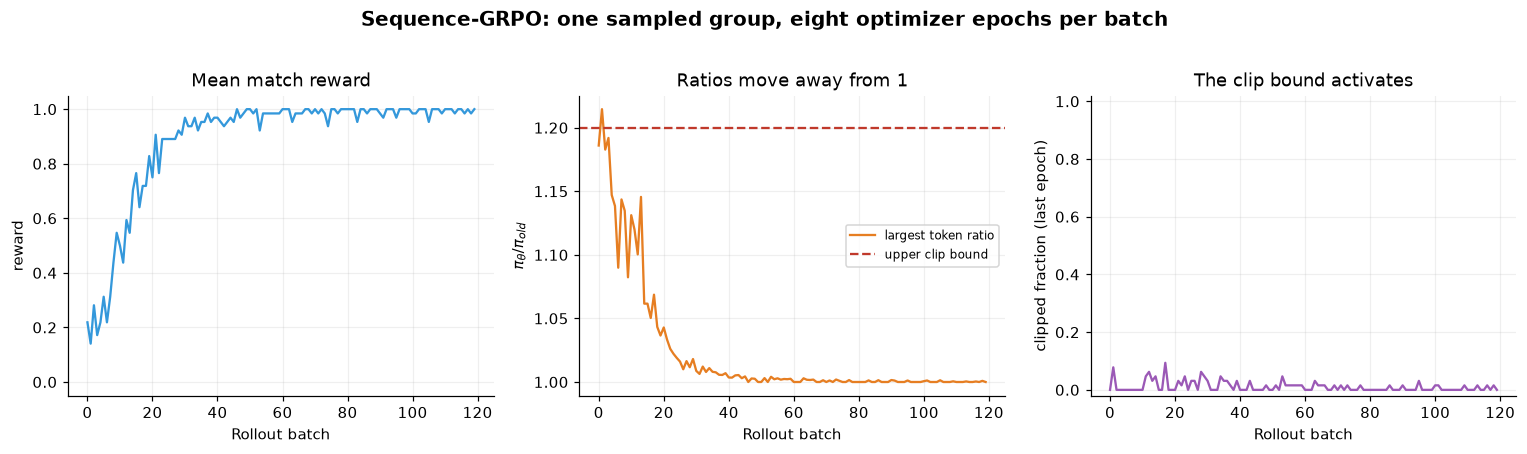

Batches with clipping: 38.3%
Final mean target-token probability: 0.993


In [6]:
np.random.seed(cfg.seed)
policy = envs.SequencePolicy(cfg.seq_length, cfg.seq_vocab_size)
ref_policy, verifier_seq = policy.copy(), envs.MatchFractionVerifier(envs.SEQ_TARGET)
history_seq = []
for step in range(120):   # 120 rollout batches, 8 optimizer epochs each
    policy, info = sequence_grpo_step(policy, ref_policy, verifier_seq, group_size=cfg.seq_group_size, lr=0.35,
                                      clip_eps=cfg.clip_eps, kl_coeff=cfg.kl_coeff, update_epochs=8)
    history_seq.append(info)
plots.sequence_training(history_seq, clip_bound=1 + cfg.clip_eps)
print(f"Batches with clipping: {np.mean([h['clip_fraction'] > 0 for h in history_seq]):.1%}")
print(f"Final mean target-token probability: "
      f"{np.mean([softmax(policy.logits[t])[envs.SEQ_TARGET[t]] for t in range(cfg.seq_length)]):.3f}")

### What We Have Built So Far

| Component | Status | Mechanism |
|---|---|---|
| **Micro-Bandit (Level A)** | Complete | Evaluates group contrast on discrete kernel configurations |
| **Micro-Sequence (Level B)** | Complete | Generates 4-stage CUDA pipelines with clipping, KL penalty, and autoregressive ratios |
| **Group-Relative Advantage** | Complete | Group mean eliminates the learned critic network |

Now that we understand how GRPO works when everything goes smoothly, continue with **`02_failure_lab.ipynb`** to see when and why it breaks.

Full references are at the end of `02_failure_lab.ipynb`.